In [2]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict, Annotated
from dotenv import load_dotenv
from pydantic import BaseModel, Field
import operator

In [3]:
load_dotenv()

True

In [4]:
model = ChatOpenAI(model_name="gpt-4o-mini")

In [17]:
class EvaluationSchema(BaseModel):

    feedback: str = Field(description="Detailed feedback for the essay")
    score: int = Field(description='Score out of 10', ge=0, le=10)

In [18]:
structured_model = model.with_structured_output(EvaluationSchema)

In [19]:
class UPSCState(TypedDict):

    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int], operator.add]
    avg_score: float

In [20]:
def evaluate_language(state: UPSCState):
    prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)

    return {'language_feedback': output.feedback, 'individual_scores' : [output.score]}

In [21]:
def evaluate_analysis(state: UPSCState):
    prompt = f'Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)
    
    return {'analysis_feedback': output.feedback, 'individual_scores' : [output.score]}

In [22]:
def evaluate_thought(state: UPSCState):
    prompt = f'Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)
    
    return {'clarity_feedback': output.feedback, 'individual_scores' : [output.score]}

In [23]:
def evaluate_final(state: UPSCState):
    # Summary feedback prompt
    prompt = f"""Based on the following feedbacks create a summarized feedback
language feedback: {state['language_feedback']}
depth of analysis feedback: {state['analysis_feedback']}
clarity of thought feedback: {state['clarity_feedback']}"""

    overall_feedback = model.invoke(prompt).content
    avg_score = sum(state['individual_scores']) / len(state['individual_scores'])

    return {
        'overall_feedback': overall_feedback,
        'avg_score': avg_score,
    }


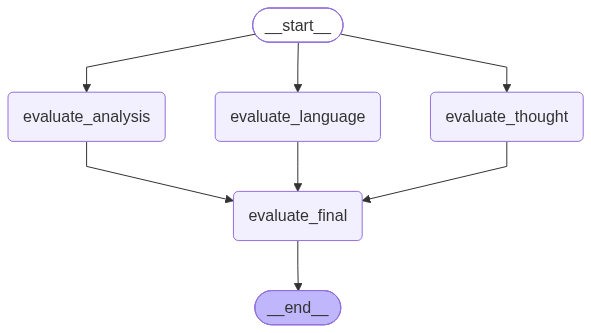

In [24]:
graph = StateGraph(UPSCState)

graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('evaluate_final', evaluate_final)


graph.add_edge(START,'evaluate_language')
graph.add_edge(START,'evaluate_analysis')
graph.add_edge(START,'evaluate_thought')

graph.add_edge('evaluate_language', 'evaluate_final')
graph.add_edge('evaluate_analysis', 'evaluate_final')
graph.add_edge('evaluate_thought', 'evaluate_final')

graph.add_edge('evaluate_final', END)

graph.compile()

In [25]:
essay = """ 
India, a burgeoning hub of technological innovation, stands at the cusp of an AI revolution. With a rapidly growing tech-savvy population and increasing digital penetration, the future of Artificial Intelligence (AI) in India is not just promising but poised for unprecedented growth. This article delves into what this future might look like.

Government Initiatives and Policies

The Indian government has been pivotal in fostering an AI-friendly ecosystem. Initiatives like 'Digital India' and the recent emphasis on AI in education reforms are testimony to this commitment. These policies are not only creating a conducive environment for AI development but also ensuring that the benefits of AI reach all sectors of society.

AI in Indian Industries

From healthcare diagnostics to precision agriculture and fintech solutions, AI's potential in various Indian industries is immense. Companies are increasingly adopting AI to enhance efficiency and customer experiences. For instance, AI-driven health-tech startups are revolutionizing patient care with personalized and accessible solutions.

Challenges and Opportunities

However, the path to AI integration in India is laden with challenges. Issues such as data privacy, a skills gap in AI technologies, and the need for robust digital infrastructure are significant hurdles. Yet, these challenges also present opportunities for innovation, job creation, and economic growth in the AI sector.

Global Collaboration and Investment

India's AI future is also being shaped by global collaborations and investments. International partnerships are bringing in both capital and expertise, accelerating India's journey towards becoming a global AI leader. These collaborations are vital for sharing knowledge and best practices in AI development and application.

Ethical Considerations and Regulation

As AI becomes more integrated into everyday life, the importance of developing and regulating AI ethically cannot be overstated. India is increasingly focusing on creating frameworks that ensure AI is used responsibly, balancing technological advancement with ethical considerations.

The future of AI in India is not just an economic narrative; it's a transformative journey that could redefine industries, governance, and daily life. With a balanced approach encompassing ethical development, regulatory frameworks, and inclusive growth, India is on its way to becoming a powerhouse in the global AI landscape.
"""

In [26]:
workflow = graph.compile()

In [27]:
initialState = {
    'essay' : essay
}

In [28]:
workflow.invoke(initialState)

{'essay': " \nIndia, a burgeoning hub of technological innovation, stands at the cusp of an AI revolution. With a rapidly growing tech-savvy population and increasing digital penetration, the future of Artificial Intelligence (AI) in India is not just promising but poised for unprecedented growth. This article delves into what this future might look like.\n\nGovernment Initiatives and Policies\n\nThe Indian government has been pivotal in fostering an AI-friendly ecosystem. Initiatives like 'Digital India' and the recent emphasis on AI in education reforms are testimony to this commitment. These policies are not only creating a conducive environment for AI development but also ensuring that the benefits of AI reach all sectors of society.\n\nAI in Indian Industries\n\nFrom healthcare diagnostics to precision agriculture and fintech solutions, AI's potential in various Indian industries is immense. Companies are increasingly adopting AI to enhance efficiency and customer experiences. For